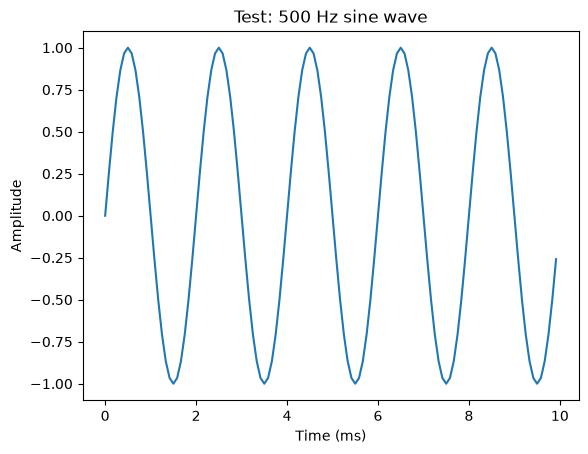

In [9]:
import numpy as np
import matplotlib.pyplot as plt

fs = 12000                      # sampling rate: 12,000 samples per second
t = np.arange(0, 0.01, 1 / fs)  # 10 ms of time
x = np.sin(2 * np.pi * 500 * t) # a 500 Hz sine wave

plt.plot(t * 1000, x)
plt.xlabel("Time (ms)")
plt.ylabel("Amplitude")
plt.title("Test: 500 Hz sine wave")
plt.show()

In [1]:
from scipy.io import loadmat
data = loadmat("../data/raw/97.mat")
print(data.keys())

dict_keys(['__header__', '__version__', '__globals__', 'X097_DE_time', 'X097_FE_time', 'X097RPM'])


In [2]:
signal = data["X097_DE_time"]
print(signal.shape)

(243938, 1)


In [3]:
print(signal.shape[0] / 12000)


20.328166666666668


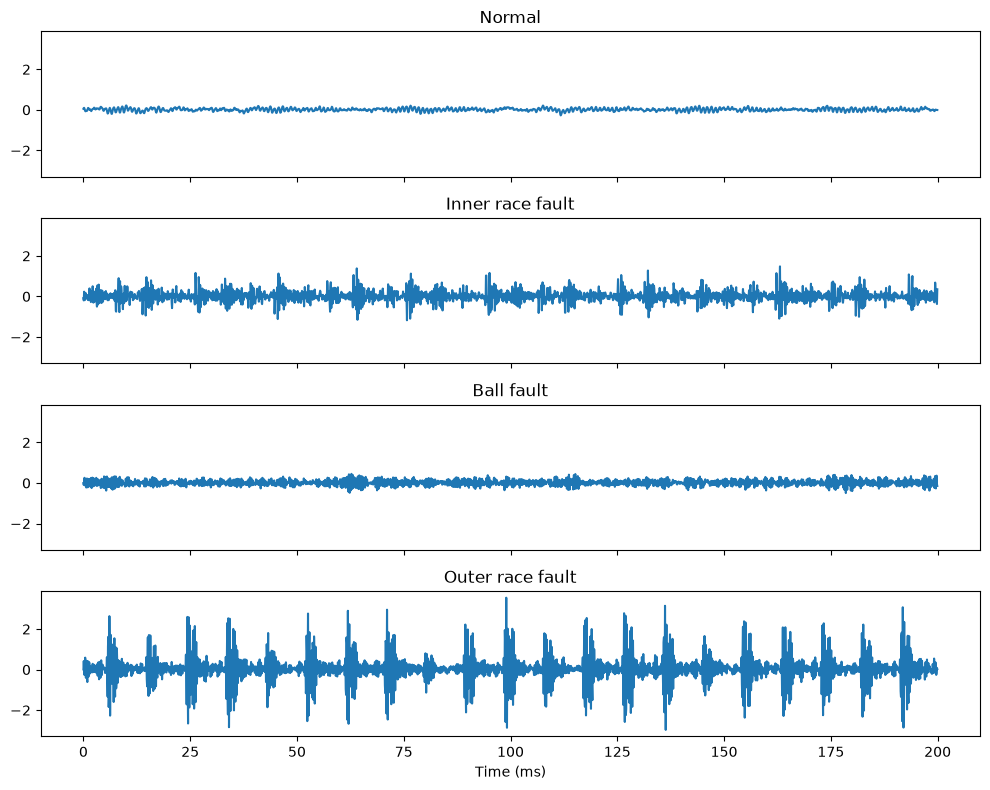

In [4]:
from scipy.io import loadmat
import matplotlib.pyplot as plt
import numpy as np

files = {"Normal": "97", "Inner race fault": "105", "Ball fault": "118", "Outer race fault": "130"}

fig, axes = plt.subplots(4, 1, figsize=(10, 8), sharex=True, sharey=True)
t = np.arange(2400) / 12000 * 1000  # first 0.2 s, in milliseconds

for ax, (label, num) in zip(axes, files.items()):
    data = loadmat(f"../data/raw/{num}.mat")
    key = [k for k in data if k.endswith("DE_time")][0]  # e.g. "X105_DE_time"
    signal = data[key].ravel()
    ax.plot(t, signal[:2400])
    ax.set_title(label)

axes[-1].set_xlabel("Time (ms)")
plt.tight_layout()
plt.show()

In [5]:
import numpy as np

def make_windows(signal, window_size, step):
    windows = []
    for start in range(0, len(signal) - window_size + 1, step):
        windows.append(signal[start: start
                               + window_size
                              ])
    return np.array(windows)

# Test with the toy example
print(make_windows(np.arange(10), window_size=4, step=2))

[[0 1 2 3]
 [2 3 4 5]
 [4 5 6 7]
 [6 7 8 9]]


In [6]:
data = loadmat("../data/raw/97.mat")
signal = data["X097_DE_time"].ravel()

windows = make_windows(signal, window_size=2048, step=2048)
print(windows.shape)

(119, 2048)


In [7]:
split = int(len(signal) * 0.8)   # index where the last 20% starts

train_part = signal[:split]
test_part  = signal[split:]    

train_windows = make_windows(train_part, window_size=2048, step=2048)
test_windows  = make_windows(test_part,  window_size=2048, step=2048)

print("train:", train_windows.shape)
print("test: ", test_windows.shape)

train: (95, 2048)
test:  (23, 2048)


In [8]:
files = {"97": 0, "105": 1, "118": 2, "130": 3}   # file number -> class label

X_train, y_train, X_test, y_test = [], [], [], []

for num, label in files.items():
    data = loadmat(f"../data/raw/{num}.mat")
    key = [k for k in data if k.endswith("DE_time")][0]
    signal = data[key].ravel()

    # 1) split FIRST (no leakage)
    split = int(len(signal) * 0.8)
    train_part = signal[:split]
    test_part  = signal[split:]

    # 2) THEN window each part separately
    tr = make_windows(train_part, window_size=2048, step=2048)
    te = make_windows(test_part,  window_size=2048, step=2048)

    # 3) store windows + a label for each window
    X_train.append(tr); y_train.append(np.full(len(tr), label))
    X_test.append(te);  y_test.append(np.full(len(te), label))

# glue the 4 lists into single arrays
X_train = np.concatenate(X_train); y_train = np.concatenate(y_train)
X_test  = np.concatenate(X_test);  y_test  = np.concatenate(y_test)

print("X_train:", X_train.shape, "y_train:", y_train.shape)
print("X_test: ", X_test.shape,  "y_test: ", y_test.shape)
print("Windows per class (train):", np.bincount(y_train))

X_train: (236, 2048) y_train: (236,)
X_test:  (56, 2048) y_test:  (56,)
Windows per class (train): [95 47 47 47]


In [10]:
from scipy.stats import kurtosis

def rms(x):
    return np.sqrt(np.mean(x ** 2))

class_names = ["Normal", "Inner race", "Ball", "Outer race"]

for label, name in enumerate(class_names):
    w = X_train[y_train == label]                 # all train windows of this class
    r = np.mean([rms(x) for x in w])              # average RMS
    k = np.mean([kurtosis(x) for x in w])         # average kurtosis
    print(f"{name:12s}  RMS = {r:.3f}   kurtosis = {k:.2f}")

Normal        RMS = 0.074   kurtosis = -0.24
Inner race    RMS = 0.291   kurtosis = 2.36
Ball          RMS = 0.138   kurtosis = -0.06
Outer race    RMS = 0.672   kurtosis = 4.60


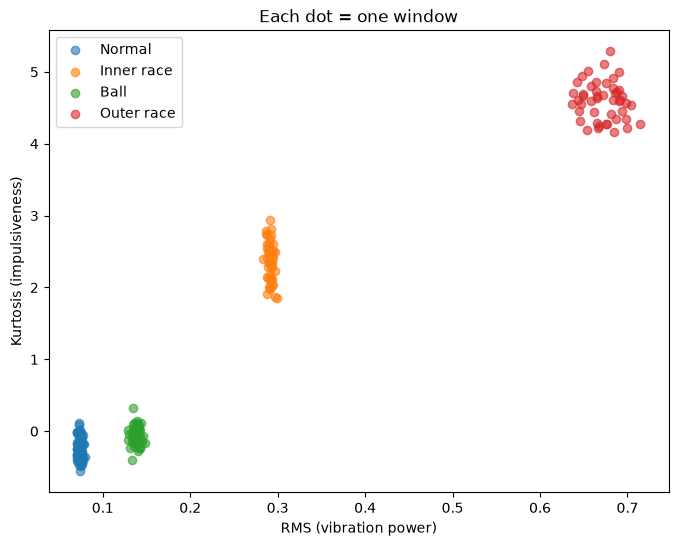

In [11]:
plt.figure(figsize=(8, 6))
for label, name in enumerate(class_names):
    w = X_train[y_train == label]
    r = [rms(x) for x in w]
    k = [kurtosis(x) for x in w]
    plt.scatter(r, k, label=name, alpha=0.6)

plt.xlabel("RMS (vibration power)")
plt.ylabel("Kurtosis (impulsiveness)")
plt.title("Each dot = one window")
plt.legend()
plt.show()

In [12]:
def extract_features(windows):
    feats = []
    for w in windows:
        r = rms(w)
        peak = np.max(np.abs(w))
        feats.append([r, kurtosis(w), peak, peak / r])
    return np.array(feats)

feature_names = ["rms", "kurtosis", "peak", "crest_factor"]

F_train = extract_features(X_train)
F_test  = extract_features(X_test)
print(F_train.shape, F_test.shape)

(236, 4) (56, 4)


In [13]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report

rf = RandomForestClassifier(n_estimators=200, random_state=42)
rf.fit(F_train, y_train)          # learn the boundaries from train windows
pred = rf.predict(F_test)         # predict test windows it has never seen

print(classification_report(y_test, pred, target_names=class_names))

              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00        23
  Inner race       1.00      1.00      1.00        11
        Ball       1.00      1.00      1.00        11
  Outer race       1.00      1.00      1.00        11

    accuracy                           1.00        56
   macro avg       1.00      1.00      1.00        56
weighted avg       1.00      1.00      1.00        56



In [ ]:
# load -> {file number: class label}
FILES = {
    0: {"97": 0, "105": 1, "118": 2, "130": 3},
    1: {"98": 0, "106": 1, "119": 2, "131": 3},
    2: {"99": 0, "107": 1, "120": 2, "132": 3},
    3: {"100": 0, "108": 1, "121": 2, "133": 3},
}

def load_windows(file_map, window_size=2048):
    X, y = [], []
    for num, label in file_map.items():
        data = loadmat(f"../data/raw/{num}.mat")
        signal = data[f"X{num.zfill(3)}_DE_time"].ravel()   # e.g. "X097_DE_time"
        w = make_windows(signal, window_size, window_size)
        X.append(w); y.append(np.full(len(w), label))
    return np.concatenate(X), np.concatenate(y)

# Train on 0 hp only
X_tr, y_tr = load_windows(FILES[0])
rf = RandomForestClassifier(n_estimators=200, random_state=42)
rf.fit(extract_features(X_tr), y_tr)

# Test on each unseen load
for load in [1, 2, 3]:
    X_te, y_te = load_windows(FILES[load])
    pred = rf.predict(extract_features(X_te))
    acc = (pred == y_te).mean()
    print(f"Train 0 hp -> Test {load} hp: accuracy = {acc:.3f}")